<a href="https://colab.research.google.com/github/Dreeaadd/Chinook-Surveys-Regression/blob/main/Chinook_Regression_Random_Seasons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

In [2]:
surveys = pd.read_csv('chinook_surveys.csv') #importing dataset

surveys.head(10) #first 10 values, for reference

,year,week,live_count,carcass_count,redd_count
0,1999,39,11,5,1
1,1999,41,69,39,45
2,1999,42,31,73,30
3,2000,38,0,0,0
4,2000,39,1,0,0
5,2000,40,4,1,0
6,2000,41,4,3,0
7,2000,42,3,2,0
8,2000,43,2,3,0
9,2000,44,1,3,0


In [3]:
np.random.seed(76) #want the seed to be the same, lebron please bless my code
years_list = surveys["year"].unique() #unique method puts only unique years in the list
np.random.shuffle(years_list) #random order

train_years = years_list[:16] #16 into training, 4 into validation, 4 into test
val_years = years_list[16:20]
test_years = years_list[20:24]

surveys_train = surveys.query("year in @train_years") #@ makes pandas not treat train_years like a string
surveys_val = surveys.query("year in @val_years")
surveys_test = surveys.query("year in @test_years")

features = ["year", "week", "live_count", "carcass_count"] #creates list for the features (really easy to adjust), and a variable for the target (if i ever want to swap around)
target = "redd_count"

train_features = torch.tensor(surveys_train[features].values, dtype=torch.float32) #feature and target tensors for training, validation, and test data
train_target = torch.tensor(surveys_train[target].values, dtype=torch.float32)

val_features = torch.tensor(surveys_val[features].values, dtype=torch.float32)
val_target = torch.tensor(surveys_val[target].values, dtype=torch.float32)

test_features = torch.tensor(surveys_test[features].values, dtype=torch.float32)
test_target = torch.tensor(surveys_test[target].values, dtype=torch.float32)

print("training features tensor size:", train_features.shape) #prints sizes and displays the tensor just to check (learned from training lab at UW)
print("training target tensor size:", train_target.shape)
print("first 10 training features + targets")
print(train_features[:10, :], train_target[:10]) #all columns and row index 0-9 for features, row index 0-9 for target

training features tensor size: torch.Size([236, 4])
training target tensor size: torch.Size([236])
first 10 training features + targets
tensor([[2.0020e+03, 3.7000e+01, 0.0000e+00, 0.0000e+00],
        [2.0020e+03, 3.8000e+01, 1.0000e+00, 1.0000e+00],
        [2.0020e+03, 3.9000e+01, 4.0000e+00, 1.0000e+00],
        [2.0020e+03, 4.0000e+01, 0.0000e+00, 0.0000e+00],
        [2.0020e+03, 4.1000e+01, 5.0000e+00, 0.0000e+00],
        [2.0020e+03, 4.2000e+01, 3.0000e+00, 4.0000e+00],
        [2.0020e+03, 4.3000e+01, 2.0000e+00, 6.0000e+00],
        [2.0020e+03, 4.4000e+01, 0.0000e+00, 0.0000e+00],
        [2.0020e+03, 4.5000e+01, 1.0000e+00, 0.0000e+00],
        [2.0020e+03, 4.6000e+01, 0.0000e+00, 0.0000e+00]]) tensor([0., 0., 0., 0., 1., 1., 3., 0., 0., 0.])


In [4]:
#i learned to define the model from University of WA EPE group internship labs
#comments explain the code to the best of my understanding (i needed to take notes)
class ReddPrediction(torch.nn.Module): #creates ReddPrediction class, which is a pytorch nn object (inherits pytorch specified capabilities but also generic ones)
  def __init__(self, in_width, out_width): #runs on any initialization of ReddPrediction
    super().__init__() #initialization code for pytorch nn module
    self.layer1 = torch.nn.Linear(in_width, 8) #first layer has input width that i can set, mapped to 8 hidden layer neurons
    self.layer2 = torch.nn.Linear(8, out_width) #maps hidden layer neurons to the output layer
    #hidden layer allows torch.nn.Linear to model complex trends (remember without hidden layer its just linear trendline)

  def forward(self, x): #defines forward pass as a function
    out = self.layer1(x) #input (x) goes layer 1 -> out
    out = self.layer2(out) #out into layer 2 -> redefines out
    return out #final output is out

in_width = len(features) #ties input layer width to the number of features specified above
model = ReddPrediction(in_width, 1) #output will always be predicted redd count

test_predict = model(train_features[:10, :]) #passes first 10 training samples through untrained model
print("model architecture:\n", model)
print("\nfirst 10 predicted redd counts (model not trained):\n", test_predict)

model architecture:
 ReddPrediction(
  (layer1): Linear(in_features=4, out_features=8, bias=True)
  (layer2): Linear(in_features=8, out_features=1, bias=True)
)

first 10 predicted redd counts (model not trained):
 tensor([[-234.0069],
        [-234.4853],
        [-235.6399],
        [-234.9532],
        [-236.6673],
        [-235.9562],
        [-235.7584],
        [-236.2151],
        [-236.8102],
        [-236.8460]], grad_fn=<AddmmBackward0>)


In [5]:
learn_rate = 0.001 #epochs and learning rate for convenient change, values recommended by lab for no overfitting
epochs = 25

mse_loss = torch.nn.MSELoss() #uses pytorch's mean squared error loss function
optimizer = torch.optim.Adam(model.parameters(), learn_rate)
#originally used stochastic gradient descent SGD (fixed learning rate).
#professor told me about adaptive moment estimate ADAM. variable learning rate is better for this type of "sparse" data (lots of 0s)

In [6]:
loss_values_train = [] #empty list to put the loss values in to plot later

#for loop below has functions i learned from labs, needed to take notes to bolster understanding
for epoch in range(epochs): #counts 0 to 99 since epochs is 100
  train_out = model(train_features) #features run through model, get labeled as output
  loss = mse_loss(train_out, train_target.reshape(-1, 1))
  #applies loss function to output and targets, reshape used to make target the same size tensor
  #-1 arg in .reshape() method makes pytorch find how many rows there are
  optimizer.zero_grad() #resets gradients to 0 every epoch, means weights will be adjusted based on that epoch's gradient values itself (instead of gradients adding by default)
  loss.backward() #backpropogation
  optimizer.step() #updates weights
  loss_values_train.append(loss.item()) #puts the epoch's loss value on the list as float because .item()

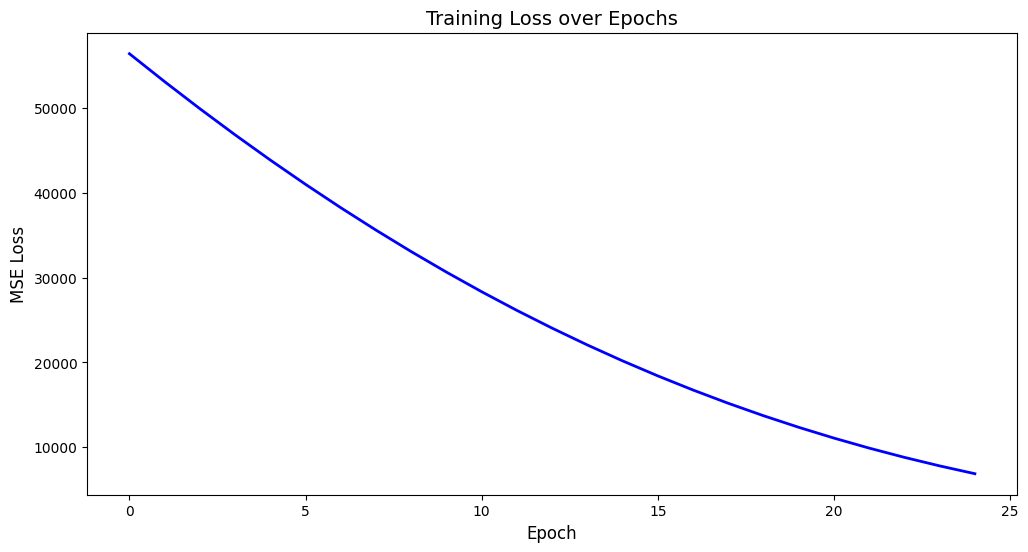

training MAE: 77.57 redds
training RMSE: 77.59 redds


In [7]:
plt.figure(figsize=(12, 6))
plt.plot(loss_values_train, label='Training Loss', color='blue', linewidth=2)

plt.title('Training Loss over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('MSE Loss', fontsize=12)

plt.show()

with torch.no_grad():
  train_est = model(train_features) #weights are frozen, makes estimates with resulting model from training
  train_mae = torch.mean(torch.abs(train_est - train_target.reshape(-1, 1))).item() #finds error of estimate and target, takes abs value, takes mean
  train_rmse = torch.sqrt(mse_loss(train_est, train_target.reshape(-1, 1))).item() #mse_loss defined earlier, just need to take sqrt of it

print(f"training MAE: {train_mae:.2f} redds")
print(f"training RMSE: {train_rmse:.2f} redds")

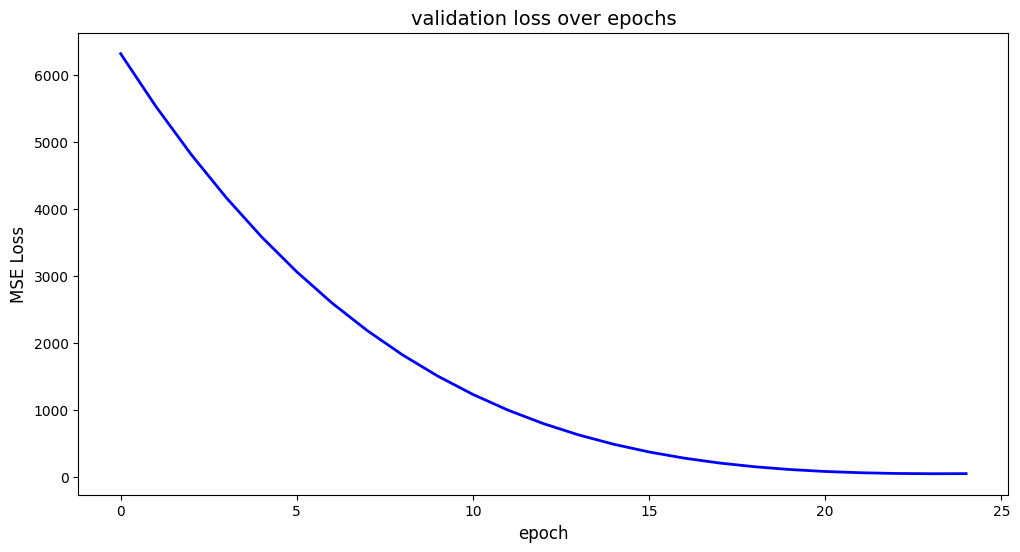


validation MAE: 4.67 redds
validation RMSE: 6.93 redds


In [8]:
loss_values_val = []

#now, run validation set through model
for epoch in range(epochs):
  val_out = model(val_features)
  loss = mse_loss(val_out, val_target.reshape(-1, 1))
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  loss_values_val.append(loss.item())

plt.figure(figsize=(12, 6)) #plot validation loss
plt.plot(loss_values_val, label='validation Loss', color='blue', linewidth=2)

plt.title('validation loss over epochs', fontsize=14)
plt.xlabel('epoch', fontsize=12)
plt.ylabel('MSE Loss', fontsize=12)

plt.show()

with torch.no_grad():
  val_est = model(val_features) #weights are frozen, estimates with end of validation weights
  val_mae = torch.mean(torch.abs(val_est - val_target.reshape(-1, 1))).item() #finds error of estimate and target, takes abs value, takes mean
  val_rmse = torch.sqrt(mse_loss(val_est, val_target.reshape(-1, 1))).item() #mse_loss defined earlier, just need to take sqrt of it

print(f"\nvalidation MAE: {val_mae:.2f} redds")
print(f"validation RMSE: {val_rmse:.2f} redds")

In [9]:
with torch.no_grad(): #test the model with test data
  test_est = model(test_features) #weights are frozen, estimates with end of test weights
  test_mae = torch.mean(torch.abs(test_est - test_target.reshape(-1, 1))).item() #finds error of estimate and target, takes abs value, takes mean
  test_rmse = torch.sqrt(mse_loss(test_est, test_target.reshape(-1, 1))).item() #mse_loss defined earlier, just need to take sqrt of it

print(f"\ntest MAE: {test_mae:.2f} redds")
print(f"test RMSE: {test_rmse:.2f} redds")


test MAE: 6.34 redds
test RMSE: 9.75 redds
